<div dir="rtl">

# کارگاه جلسه ۲۴ — ماشین بردار پشتیبان

هر بخش مستقل است. نوشتن این کدها در امتحان پرسیده نمی‌شود.

1. اثر C بر پهنای حاشیه و تعداد بردارهای پشتیبان
2. نگاشت صریح در برابر ترفند هسته
3. تمرین عملی کلاس: مقایسه هسته‌ها روی داده غیرخطی

</div>

<div dir="rtl">

## ۱. اثر C بر حاشیه

دو خوشه هم‌پوشان (`make_blobs`) با هسته خطی؛ برای هر C پهنای حاشیه (دو تقسیم بر نُرم w) و تعداد بردارهای پشتیبان را می‌بینیم.

</div>

In [1]:
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

X, y = make_blobs(n_samples=200, centers=2, cluster_std=3, random_state=42)
for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    svm = SVC(kernel="linear", C=C).fit(X, y)
    print(f"C={C:<6} support vectors={svm.n_support_.sum():3d}  margin={2 / np.linalg.norm(svm.coef_):.2f}  "
          f"train accuracy={svm.score(X, y):.3f}")

C=0.001  support vectors= 85  margin=9.27  train accuracy=0.975
C=0.01   support vectors= 36  margin=5.19  train accuracy=0.970
C=0.1    support vectors= 22  margin=2.96  train accuracy=0.960
C=1      support vectors= 18  margin=2.71  train accuracy=0.960
C=10     support vectors= 18  margin=2.71  train accuracy=0.960
C=100    support vectors= 17  margin=1.88  train accuracy=0.965


<div dir="rtl">

## ۲. نگاشت صریح در برابر ترفند هسته

روی دو دایره هم‌مرکز، ویژگی سوم «مجذور فاصله از مرکز» را **دستی** می‌سازیم و SVM خطی را آموزش می‌دهیم؛ سپس با SVM هسته چندجمله‌ای درجه ۲ روی ویژگی‌های اصلی مقایسه می‌کنیم.

</div>

In [2]:
import numpy as np
from sklearn.datasets import make_circles
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.svm import SVC

X, y = make_circles(n_samples=300, noise=0.1, factor=0.4, random_state=42)
add_r2 = FunctionTransformer(lambda Z: np.c_[Z, (Z ** 2).sum(axis=1)])     # rule-based feature
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = {"linear on (x1, x2)": make_pipeline(StandardScaler(), SVC(kernel="linear")),
          "linear on (x1, x2, r^2)": make_pipeline(add_r2, StandardScaler(), SVC(kernel="linear")),
          "poly kernel d=2 on (x1, x2)": make_pipeline(StandardScaler(), SVC(kernel="poly", degree=2))}
for name, m in models.items():
    print(f"{name:28s} CV accuracy={cross_val_score(m, X, y, cv=cv).mean():.3f}")

linear on (x1, x2)           CV accuracy=0.513
linear on (x1, x2, r^2)      CV accuracy=1.000
poly kernel d=2 on (x1, x2)  CV accuracy=0.997


<div dir="rtl">

## ۳. تمرین عملی کلاس (۲۵ دقیقه)

داده دو دایره را با `make_circles(n_samples=500, noise=0.2, factor=0.5, random_state=0)` بسازید (هم‌پوشانی بیشتر از جزوه) و با ۳۰ درصد آزمون (طبقه‌بندی‌شده، `random_state=42`) تقسیم کنید.

1. دقت اعتبارسنجی ۵ بخشی SVM با هسته خطی، چندجمله‌ای درجه ۲ و ۳ و RBF (پیش‌فرض) را مقایسه کنید.
2. برای هسته RBF، C و gamma را روی شبکه لگاریتمی (C از ۰.۰۱ تا ۱۰۰۰ و gamma از ۰.۰۱ تا ۱۰۰) تنظیم کنید و نقشه حرارتی دقت اعتبارسنجی را رسم کنید.
3. دقت آزمون بهترین مدل را با k-NN (k تنظیم‌شده) مقایسه کنید.
4. اگر مقیاس ویژگی دوم را ۱۰۰ برابر کنیم و استانداردسازی نکنیم، دقت RBF چه می‌شود؟

</div>

In [3]:
# Write your solution here

<div dir="rtl">

### پاسخ تمرین

</div>

linear    CV accuracy=0.560
poly d=2  CV accuracy=0.883
poly d=3  CV accuracy=0.626
rbf       CV accuracy=0.877


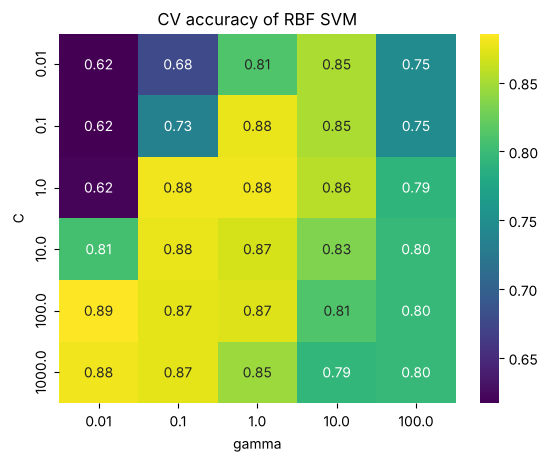

SVM best={'C': 100.0, 'gamma': 0.01}  test=0.907
k-NN best k=21  test=0.900
RBF, second feature x100, no scaling: CV=0.711


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

X, y = make_circles(n_samples=500, noise=0.2, factor=0.5, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, svc in {"linear": SVC(kernel="linear"), "poly d=2": SVC(kernel="poly", degree=2),
                  "poly d=3": SVC(kernel="poly", degree=3), "rbf": SVC()}.items():
    acc = cross_val_score(make_pipeline(StandardScaler(), svc), X_train, y_train, cv=cv).mean()
    print(f"{name:9s} CV accuracy={acc:.3f}")

grid = {"svc__C": np.logspace(-2, 3, 6), "svc__gamma": np.logspace(-2, 2, 5)}
gs = GridSearchCV(make_pipeline(StandardScaler(), SVC()), grid, cv=cv).fit(X_train, y_train)
heat = pd.DataFrame(gs.cv_results_["mean_test_score"].reshape(6, 5),
                    index=np.logspace(-2, 3, 6), columns=np.logspace(-2, 2, 5))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="viridis")
plt.xlabel("gamma"); plt.ylabel("C"); plt.title("CV accuracy of RBF SVM")
plt.show()
knn = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()),
                   {"kneighborsclassifier__n_neighbors": range(1, 52, 2)}, cv=cv).fit(X_train, y_train)
print(f"SVM best={ {k.split('__')[1]: float(v) for k, v in gs.best_params_.items()} }  test={gs.score(X_test, y_test):.3f}")
print(f"k-NN best k={knn.best_params_['kneighborsclassifier__n_neighbors']}  test={knn.score(X_test, y_test):.3f}")

X_bad = X_train * np.array([1, 100])
print(f"RBF, second feature x100, no scaling: CV={cross_val_score(SVC(), X_bad, y_train, cv=cv).mean():.3f}")

<div dir="rtl">

### پاسخ‌های کلیدی

- بخش ۱: با افزایش C از ۰.۰۰۱ به ۱۰۰، پهنای حاشیه از ۹.۲۷ به ۱.۸۸ و تعداد بردارهای پشتیبان از ۸۵ به ۱۷ کم می‌شود؛ دقت آموزش در این داده تقریباً خطی تقریباً ثابت است.
- بخش ۲: SVM خطی روی (x1، x2) دقت ۰.۵۱۳ دارد؛ با افزودن دستی ویژگی «مجذور فاصله» به **۱.۰۰۰** می‌رسد. هسته چندجمله‌ای درجه ۲ همین کار را بدون ساختن ویژگی انجام می‌دهد (۰.۹۹۷).
- تمرین: دقت اعتبارسنجی خطی ۰.۵۶۰، چندجمله‌ای درجه ۲ **۰.۸۸۳**، درجه ۳ ۰.۶۲۶ و RBF **۰.۸۷۷**. درجه ۳ (فرد) شکل متقارن دایره‌ها را نمی‌گیرد.
- نقشه حرارتی: ناحیه خوب نواری مورب است؛ C بزرگ با gamma کوچک یا C متوسط با gamma متوسط. بهترین ترکیب C برابر ۱۰۰ و gamma برابر ۰.۰۱ است: C و gamma با هم تعامل دارند.
- دقت آزمون SVM **۰.۹۰۷** و k-NN با k برابر ۲۱ حدود ۰.۹۰۰؛ تقریباً یکسان.
- با ضرب ویژگی دوم در ۱۰۰ و بدون استانداردسازی، دقت اعتبارسنجی RBF به **۰.۷۱۱** سقوط می‌کند: فاصله‌ها تقریباً فقط به ویژگی دوم بستگی دارند.

</div>